# SOLUCIÓN (uso docente): Bienestar Activo
Una línea de trabajo razonable; hay otras válidas si están justificadas.

*El enunciado es el mismo del notebook de partida.*

In [66]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score, adjusted_rand_score, classification_report, average_precision_score, precision_recall_curve
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("estudiantes_salud.csv")
df.head()

,id_estudiante,sede,genero,edad,talla_m,peso_kg,antec_familiar,come_calorico,verduras,comidas_principales,picoteo,fuma,agua,controla_calorias,actividad_fisica,pantallas,alcohol,transporte,categoria_peso
0,1,Sur,Masculino,17.000000,1.620000,69.000000,Si,Si,3.00000,1.000000,Siempre,No,NaN,Si,1.000000,2.000000,A VECES,Transporte_publico,Sobrepeso_I
1,2,Central,Masculino,21.123048,1.717037,80.000000,Si,Si,2.00000,3.000000,a veces,No,2.000000,No,2.270555,1.343044,Nunca,Transporte_publico,Sobrepeso_II
2,3,Sur,M,39.759575,1.792507,101.780099,Si,Si,2.33361,2.113575,A veces,No,2.504136,No,2.998981,1.000000,A veces,Auto,Obesidad_I
3,4,Sur,Masculino,20.000000,1.800000,85.000000,Si,No,2.00000,3.000000,a veces,No,NaN,No,2.000000,1.000000,A veces,Transporte_publico,Sobrepeso_I
4,5,Sur,Femenino,19.220108,1.530266,42.000000,No,SI,3.00000,1.000000,Frecuente,No,NaN,No,0.000000,0.907868,A veces,Transporte_publico,Peso_insuficiente


## 1. Conocimiento de los datos

In [3]:
df.info()
df.describe().T.round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id_estudiante        1480 non-null   int64  
 1   sede                 1480 non-null   object 
 2   genero               1480 non-null   object 
 3   edad                 1480 non-null   float64
 4   talla_m              1480 non-null   float64
 5   peso_kg              1480 non-null   float64
 6   antec_familiar       1480 non-null   object 
 7   come_calorico        1480 non-null   object 
 8   verduras             1480 non-null   float64
 9   comidas_principales  1480 non-null   float64
 10  picoteo              1480 non-null   object 
 11  fuma                 1480 non-null   object 
 12  agua                 1363 non-null   float64
 13  controla_calorias    1480 non-null   object 
 14  actividad_fisica     1379 non-null   float64
 15  pantallas            1384 non-null   f

,count,mean,std,min,25%,50%,75%,max
id_estudiante,1480.0,740.50,427.38,1.00,370.75,740.50,1110.25,1480.00
edad,1480.0,25.29,21.21,0.00,19.14,21.81,26.00,300.00
talla_m,1480.0,51.92,77.04,1.45,1.66,1.75,160.00,193.00
peso_kg,1480.0,77.05,23.43,39.00,59.25,75.00,87.86,165.06
verduras,1480.0,2.37,0.54,1.00,2.00,2.22,3.00,3.00
comidas_principales,1480.0,2.67,0.84,1.00,2.47,3.00,3.00,4.00
agua,1363.0,2.00,0.61,1.00,1.60,2.00,2.41,3.00
actividad_fisica,1379.0,1.05,0.88,0.00,0.14,1.00,1.88,3.00
pantallas,1384.0,0.69,0.63,0.00,0.00,0.71,1.00,2.00


`talla_m` tiene valores de hasta ~190 y `edad` tiene valores imposibles (0, 1, 210...). Hay nulos en `actividad_fisica`, `agua` y `pantallas`. Investigamos cada caso.

In [4]:
print('Talla por sede (mediana):'); print(df.groupby('sede')['talla_m'].median(), '\n')
print('Edades fuera de rango:', sorted(df.loc[(df.edad<14)|(df.edad>80),'edad'].unique()))
print('\nNulos (%) por sede:'); print((df[['actividad_fisica','agua','pantallas']].isna().groupby(df['sede']).mean()*100).round(1))
for c in ['genero','come_calorico','alcohol','picoteo']: print('\n', df[c].value_counts().to_dict())
print('\nDuplicados (sin id):', df.drop(columns='id_estudiante').duplicated().sum())
print('Ordinales con decimales (verduras):', (df['verduras'].dropna()%1!=0).mean().round(2))

Talla por sede (mediana):
sede
Central      1.7
Norte      170.0
Sur          1.7
Name: talla_m, dtype: float64 

Edades fuera de rango: [np.float64(0.0), np.float64(1.0), np.float64(190.0), np.float64(210.0), np.float64(230.0), np.float64(300.0)]

Nulos (%) por sede:
         actividad_fisica  agua  pantallas
sede                                      
Central               4.7   6.0        5.3
Norte                 6.8   7.0        4.3
Sur                  12.5  14.2       12.8

 {'Femenino': 463, 'Masculino': 445, 'masculino': 121, 'M': 108, 'F': 108, 'femenino': 101, 'mujer': 69, 'Varón': 65}

 {'Si': 1011, 'No': 193, 'Sí': 127, 'SI': 110, 'NO': 20, 'no': 19}

 {'A veces': 763, 'Nunca': 399, 'a veces': 89, 'A VECES': 86, 'Frecuente': 48, 'NUNCA': 46, 'nunca': 36, 'FRECUENTE': 7, 'frecuente': 5, 'Siempre': 1}

 {'A veces': 920, 'Frecuente': 197, 'A VECES': 117, 'a veces': 109, 'Nunca': 40, 'Siempre': 36, 'frecuente': 21, 'FRECUENTE': 19, 'nunca': 7, 'SIEMPRE': 6, 'NUNCA': 4, 'siempre

**Problemas y decisiones**

| Problema | Decisión 
|---|---|
| Sede Norte carga la talla en cm | Dividir por 100 en esa sede 
| Edades imposibles (0, 1, 190-300) | Pasar a nulo (el rango real es 14-61) y tratar como faltante | 
| ~8% de nulos, más en sede Sur (no aleatorio) | reemplazar con la medidana del pipeline | 
| `genero`, `come_calorico`, `alcohol`, `picoteo` incosistentes | Unificar con minúsculas y un mapeo | 
| Ordinales con decimales en un cuestionario de respuestas enteras | Se mantienen y se discute: el dataset original mezcla datos sintéticos  |
| Pocos duplicados | Eliminar | 
| Clase obesidad ~23% | Estratificar y usar métricas para desbalance |

In [7]:
# A mi me gusta usar polars para hacer estas transformaciones, es mucho mas legible
import polars as pl

In [30]:
niv = {'nunca':0,'a veces':1,'frecuente':2,'siempre':3}


In [41]:
d = pl.from_dataframe(df)
d = d.with_columns(
    talla_m = pl.when(
        pl.col('sede') == 'Norte'
    ).then(
        pl.col('talla_m')/100
    ).otherwise(
        pl.col('talla_m')
    ),

    edad = pl.when(
        pl.col('edad').is_between(14, 80)
    ).then(
        pl.col("edad")
    ), # En caso contrario, null

    genero = pl.when(
        pl.col('genero').str.to_lowercase().is_in({'femenino', 'f', 'mujer'})
    ).then(
        pl.lit("F")
    ).otherwise(pl.lit('M')),

    come_calorico = pl.when(pl.col('come_calorico').str.to_lowercase().str.starts_with('s') ).then(1).otherwise(0),
    antec_familiar = pl.when(pl.col('antec_familiar').str.to_lowercase().str.starts_with('s')).then(1).otherwise(0),
    fuma = pl.when(pl.col('fuma').str.to_lowercase().str.starts_with('s') ).then(1).otherwise(0),
    controla_calorias = pl.when(pl.col('controla_calorias').str.to_lowercase().str.starts_with('s') ).then(1).otherwise(0),

    picoteo = pl.col('picoteo').str.to_lowercase().replace(niv),
    alcohol = pl.col('alcohol').str.to_lowercase().replace(niv),
    obsesidad = pl.when(pl.col('categoria_peso').str.starts_with('Obesidad')).then(1).otherwise(0)
).drop_nans()
d = d.to_pandas()

In [43]:
print(d.shape, '| obesidad:', d['obesidad'].mean().round(3))

d.isna().sum()[lambda s: s>0]

(1470, 20) | obesidad: 0.232


edad                 14
agua                117
actividad_fisica    100
pantallas            96
dtype: int64

In [59]:
#version en pandas 

d = df.copy()

d.loc[d['sede']=='Norte', 'talla_m'] /= 100

d.loc[(d['edad']<14)|(d['edad']>80), 'edad'] = np.nan

d['genero'] = d['genero'].str.lower().map(lambda v: 'F' if v in ('femenino','f','mujer') else 'M')

d['come_calorico'] = d['come_calorico'].str.lower().map({'si':1,'sí':1,'no':0})

for c in ['antec_familiar','fuma','controla_calorias']: 
    d[c] = (d[c]=='Si').astype(int)

niv = {'nunca':0,'a veces':1,'frecuente':2,'siempre':3}

for c in ['picoteo','alcohol']: 
    d[c] = d[c].str.lower().map(niv)

d = d.drop_duplicates(subset=[c for c in d.columns if c!='id_estudiante']).reset_index(drop=True)

d['obesidad'] = d['categoria_peso'].str.startswith('Obesidad').astype(int)

print(d.shape, '| obesidad:', d['obesidad'].mean().round(3))

d.isna().sum()[lambda s: s>0]

(1470, 20) | obesidad: 0.232


edad                 14
agua                117
actividad_fisica    100
pantallas            96
dtype: int64

## 2. Agrupamiento
No usaremos `peso_kg`, `talla_m` ni `categoria_peso` porque nos pide solo el perfil por habitos. Tampoco usamos `sede` ni `id`. Las variables se imputan con mediana y se estandarizan (si no, `edad` dominaría por su escala).

In [46]:
habitos = ['verduras','comidas_principales','picoteo','agua','actividad_fisica','pantallas','alcohol',
       'come_calorico','controla_calorias','antec_familiar','edad']

# Podemos usar una pipeline para hacer todo el preprocesamiento, luego podemos reutilizar este pipeline. 
# Si hay un dato faltante, imputaremos usando la mediana y vamos a estandarizar. Como tenemos booleanos, pueden dominar tambien asi que vamos a usar StandarScaler
Xs = make_pipeline(SimpleImputer(strategy='median'), StandardScaler()).fit_transform(d[habitos])



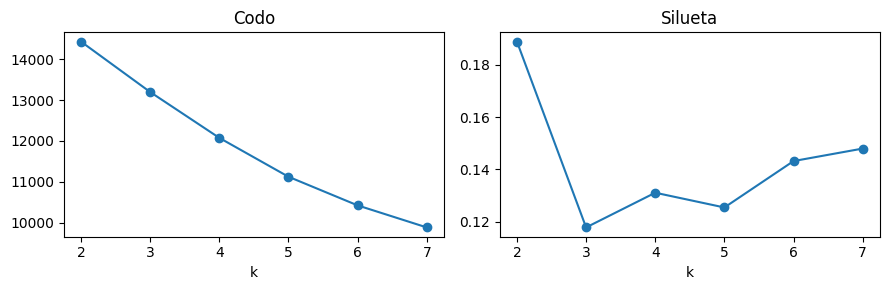

{2: np.float64(0.189), 3: np.float64(0.118), 4: np.float64(0.131), 5: np.float64(0.125), 6: np.float64(0.143), 7: np.float64(0.148)}


In [49]:
ks = range(2, 8); inercia=[]; sil=[]
for k in ks:
    km = KMeans(k, n_init=10).fit(Xs)
    inercia.append(km.inertia_)
    sil.append(silhouette_score(Xs, km.labels_))
fig, ax = plt.subplots(1,2, figsize=(9,3))
ax[0].plot(ks, inercia, 'o-'); ax[0].set_title('Codo'); ax[0].set_xlabel('k')
ax[1].plot(ks, sil, 'o-'); ax[1].set_title('Silueta'); ax[1].set_xlabel('k')

plt.tight_layout(); 
plt.show(); 
print(dict(zip(ks, np.round(sil,3))))

La silueta es baja en todos los casos (< 0,25): **no hay grupos naturales muy marcados**. El codo no muestra un quiebre claro. Elegimos **k = 4** por que si nomas, cualquier valor puede ser utilizable. 
En este caso, como no hay grupos muy marcados, podemos usar el K que nos de el negocio en funcion de cuantos talleres queremos usar.

In [51]:
km = KMeans(4, n_init=10).fit(Xs)
d['cluster'] = km.labels_

perfil = d.groupby('cluster')[habitos+['obesidad']].mean().round(2)

perfil['n'] = d['cluster'].value_counts().sort_index()
perfil.rename(columns={'obesidad':'prop_obesidad'}).T

cluster,0,1,2,3
verduras,2.35,2.37,2.35,2.60
comidas_principales,2.63,2.52,2.89,2.63
picoteo,1.39,1.02,1.24,1.38
agua,1.71,1.98,2.14,2.08
actividad_fisica,1.12,0.64,1.41,1.31
pantallas,0.72,0.41,1.01,0.60
alcohol,0.75,0.86,0.53,0.75
come_calorico,0.75,0.94,0.84,0.61
controla_calorias,0.00,0.00,0.00,1.00
antec_familiar,0.00,0.96,1.00,0.49


**Lectura de los grupos** (los números pueden variar con la semilla; lo importante es el perfil):

- **Adultos con antecedentes y poca actividad:** mayor edad media (~29), antecedentes familiares casi universales, la menor actividad física y la **mayor proporción de obesidad (~40%)**. *Taller:* actividad física y alimentación para adultos.
- **Jóvenes con antecedentes, más activos y con más pantallas:** ~21 años, antecedentes familiares, más tiempo en pantallas y menos alcohol; obesidad intermedia (~17%). *Taller:* prevención, hábitos de sueño y pantallas.
- **Sin antecedentes familiares:** obesidad prácticamente nula (~1%). *Acción:* seguimiento mínimo.
- **Quienes controlan sus calorías:** grupo pequeño con obesidad muy baja (~2%). *Acción:* reforzar y usar como referencia.

**Estabilidad:** el ARI de la celda siguiente es moderado (~0,6): los grupos grandes se reproducen, pero las fronteras cambian. Es una limitación a mencionar.

**Advertencia metodológica:** los grupos están muy influidos por las variables binarias (`controla_calorias`, `antec_familiar`), que al estandarizarse pesan mucho.

## 3. Predicción de obesidad

**Variable objetivo:** `obesidad` = 1 si `categoria_peso` es Obesidad_I, II o III.
Como tenemos que decidir nomas a quien invitar, no nos importa el tipo de la categoria de obesidad.

**Qué variables usar:**
- `categoria_peso`: es la respuesta hay que sacarla si ya tenemos obesidad, porque sino habria una correlacion muy marcada y poco interesante. 
- `peso_kg` y `talla_m`: se miden en el consultorio, después del cuestionario y la categoría se calcula a partir del IMC. Tambien estan correlacionados asi que los sacamos
- `sede` e `id_estudiante`: no son hábitos y no deberían explicar la obesidad.
- Resto del cuestionario, `edad`, `genero` y `transporte` pueden ser utiles

Nos importa medir el recall y la precision.
Nos importa no errar a los positivos. Los falsos negativos son mas costosos, por lo que queremos un recall alto aunque la precisión sea baja. 

In [65]:
d_prep = pd.concat([d, pd.get_dummies(d['transporte'], prefix='t', dtype=int)], axis=1)
d_prep = d_prep.drop('transporte', axis=1)
d_prep

,id_estudiante,sede,genero,edad,talla_m,peso_kg,antec_familiar,come_calorico,verduras,comidas_principales,...,actividad_fisica,pantallas,alcohol,categoria_peso,obesidad,t_Auto,t_Bicicleta,t_Caminando,t_Moto,t_Transporte_publico
0,1,Sur,M,17.000000,1.620000,69.000000,1,1,3.00000,1.000000,...,1.000000,2.000000,1,Sobrepeso_I,0,0,0,0,0,1
1,2,Central,M,21.123048,1.717037,80.000000,1,1,2.00000,3.000000,...,2.270555,1.343044,0,Sobrepeso_II,0,0,0,0,0,1
2,3,Sur,M,39.759575,1.792507,101.780099,1,1,2.33361,2.113575,...,2.998981,1.000000,1,Obesidad_I,1,1,0,0,0,0
3,4,Sur,M,20.000000,1.800000,85.000000,1,0,2.00000,3.000000,...,2.000000,1.000000,1,Sobrepeso_I,0,0,0,0,0,1
4,5,Sur,F,19.220108,1.530266,42.000000,0,1,3.00000,1.000000,...,0.000000,0.907868,1,Peso_insuficiente,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,1476,Central,M,18.164768,1.694265,52.000000,1,1,3.00000,3.000000,...,0.819682,1.000000,0,Peso_insuficiente,0,0,0,0,0,1
1466,1477,Central,M,23.000000,1.650000,66.000000,0,0,3.00000,3.000000,...,3.000000,0.000000,0,Peso_normal,0,0,0,0,0,1
1467,1478,Central,F,16.270434,1.818268,47.124717,0,1,3.00000,3.286431,...,2.458237,1.273333,1,Peso_insuficiente,0,0,0,0,0,1
1468,1479,Central,M,18.000000,1.710800,50.925380,1,1,2.00000,3.000000,...,0.000000,1.593704,1,Peso_insuficiente,0,0,0,0,0,1


In [68]:
base = habitos + [c for c in d_prep if c.startswith('t_')]

y = d['obesidad']

print(base)

['verduras', 'comidas_principales', 'picoteo', 'agua', 'actividad_fisica', 'pantallas', 'alcohol', 'come_calorico', 'controla_calorias', 'antec_familiar', 'edad', 't_Auto', 't_Bicicleta', 't_Caminando', 't_Moto', 't_Transporte_publico']


In [77]:
def modelo(trees):
    return make_pipeline(SimpleImputer(strategy='median'),
        RandomForestClassifier(trees, min_samples_leaf=3, class_weight='balanced'))


In [79]:
scores = cross_val_score(modelo(10), d_prep[base], y,  scoring='recall')
print(f'Promedio {np.mean(scores)} +/- {np.std(scores)}')

scores = cross_val_score(modelo(50), d_prep[base], y,  scoring='recall')
print(f'Promedio {np.mean(scores)} +/- {np.std(scores)}')

scores = cross_val_score(modelo(100), d_prep[base], y,  scoring='recall')
print(f'Promedio {np.mean(scores)} +/- {np.std(scores)}')

scores = cross_val_score(modelo(250), d_prep[base], y,  scoring='recall')
print(f'Promedio {np.mean(scores)} +/- {np.std(scores)}')

Promedio 0.7683290707587382 +/- 0.03401497135643488
Promedio 0.7918158567774936 +/- 0.0167543583861381
Promedio 0.7742114236999147 +/- 0.03775991546004359
Promedio 0.7858908780903666 +/- 0.06290144860775533


Aca antes calculamos el recall para la clase positiva (1), que es "obesidad"

In [91]:
X_train, X_test, y_train, y_test, = train_test_split(d_prep[base], y, train_size=0.9, stratify=y)
modelo_final = modelo(50).fit(X_train, y_train)

In [92]:
pred = modelo_final.predict(X_test)

print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.93      0.97      0.95       113
           1       0.90      0.76      0.83        34

    accuracy                           0.93       147
   macro avg       0.91      0.87      0.89       147
weighted avg       0.92      0.93      0.92       147

